# Walkthrough: Did Illinois's 36% rate cap close Chicago's payday lenders?

This notebook walks through the project step by step, using the files that `src/run_all.py` produces.
It doesn't download anything, so it runs in seconds. To rebuild everything from scratch first, run
`python src/run_all.py` from the project folder.

**Questions**
1. Where were high-cost lenders before the law (March 23, 2021)?
2. Did they close after it, and is the law the likely cause?
3. Did pawnshops fill the gap?

In [1]:
import sys
from pathlib import Path

import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))      # so we can reuse the project's own code
from analysis_data import load_tracts, load_panel

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RESULTS, FIGURES = ROOT / "results", ROOT / "figures"

## Step 1 - The data: lender storefronts from city business licenses

Illinois hasn't published lender branch addresses since 2011, so we use City of Chicago business licenses.
A **storefront** is one type of lender at one street address, followed across license renewals and changes of owner.
A store counts as open on a date if it held a license covering that date.

In [2]:
stores = pd.read_csv(ROOT / "data/clean/storefronts.csv")
stores.groupby("category")[["active_pre", "active_law", "active_post"]].sum().rename(columns={
    "active_pre": "Jan 1, 2020", "active_law": "Mar 23, 2021 (law)", "active_post": "Jan 1, 2024"})

,"Jan 1, 2020","Mar 23, 2021 (law)","Jan 1, 2024"
category,,,
high_cost,67,65,1
lower_cost,0,0,0
pawn,60,58,49
uncertain,4,3,2


### Can we trust city licenses? A validation check

The Wayback Machine saved the state regulator's (IDFPR) licensee list as of April 5, 2011.
For each Chicago branch on it, did the city have a business license at the same address on that date?

In [3]:
check = pd.read_csv(ROOT / "data/clean/validation_2011_coverage.csv")
branches = check[~check["head_office"]]
pd.DataFrame({
    "branches on state list": [len(branches), branches["high_cost_type"].sum()],
    "found in city licenses": [branches["found_in_city_licenses"].sum(),
                               branches.loc[branches["high_cost_type"], "found_in_city_licenses"].sum()],
}, index=["All consumer-credit branches", "Payday / title / cash-advance"]).assign(
    coverage=lambda d: d["found in city licenses"] / d["branches on state list"])

,branches on state list,found in city licenses,coverage
All consumer-credit branches,137,123,0.898
Payday / title / cash-advance,84,80,0.952


## Step 2 - Question 1: where were high-cost lenders in January 2020?

First, simple counting: does each group's share of the stores match its share of Chicago's residents?

In [4]:
exposure = pd.read_csv(RESULTS / "exposure_by_majority_group.csv", index_col=0)
exposure[["residents", "stores_2020", "share_of_residents", "share_of_stores", "stores_per_100k"]]

,residents,stores_2020,share_of_residents,share_of_stores,stores_per_100k
majority_group,,,,,
Majority Black,742838,21,0.272,0.313,2.827
Majority Latino,657430,10,0.241,0.149,1.521
Majority white,903333,23,0.331,0.343,2.546
No majority,426788,13,0.156,0.194,3.046


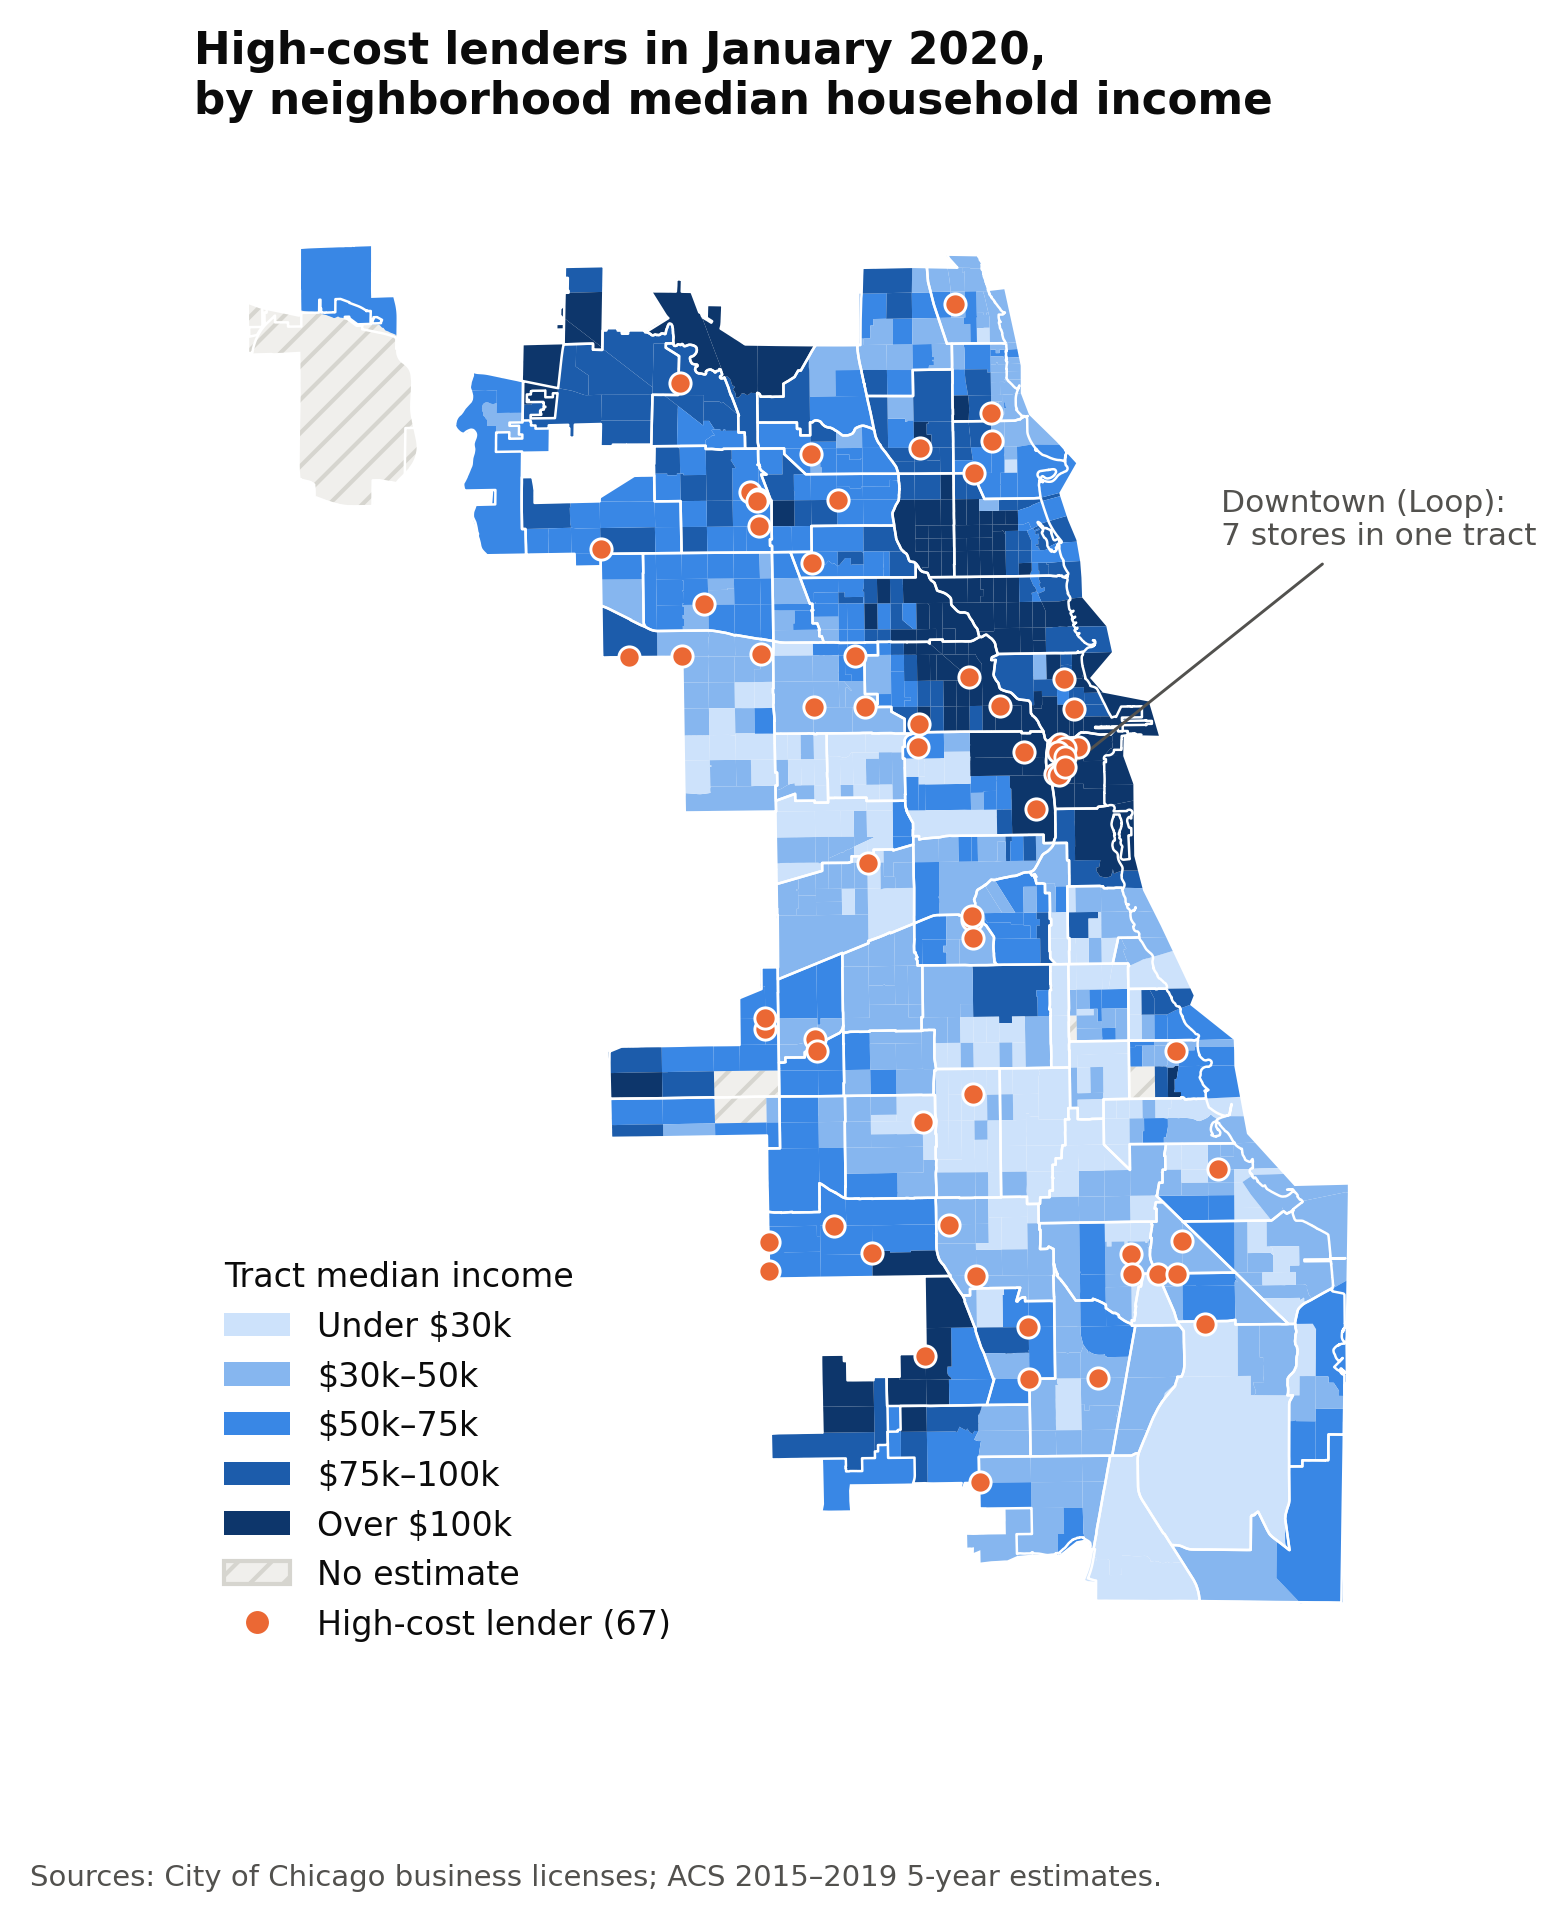

In [5]:
display(Image(FIGURES / "fig1_map_income.png", width=500))

### One model, fitted live

Logistic regression for "does this tract have at least one high-cost store?".
The **odds ratio** for each predictor is `exp(coefficient)`; 1.0 means no relationship.
`log_businesses` controls for how commercial the tract is. Standard errors are clustered by community area.

In [6]:
import numpy as np

tracts = load_tracts()
fit = smf.logit("any_high_cost_pre ~ income_10k + black_10pp + latino_10pp + log_businesses",
                data=tracts).fit(disp=False, cov_type="cluster",
                                 cov_kwds={"groups": tracts["community_area"]})
pd.DataFrame({"odds_ratio": np.exp(fit.params), "ci_low": np.exp(fit.conf_int()[0]),
              "ci_high": np.exp(fit.conf_int()[1]), "p_value": fit.pvalues}).drop("Intercept")

,odds_ratio,ci_low,ci_high,p_value
income_10k,1.007,0.875,1.159,0.920
black_10pp,1.182,1.040,1.342,0.010
latino_10pp,1.072,0.920,1.250,0.373
log_businesses,3.366,2.367,4.788,0.000


Every specification (see `src/analysis_models.py`) gives the same overall picture:

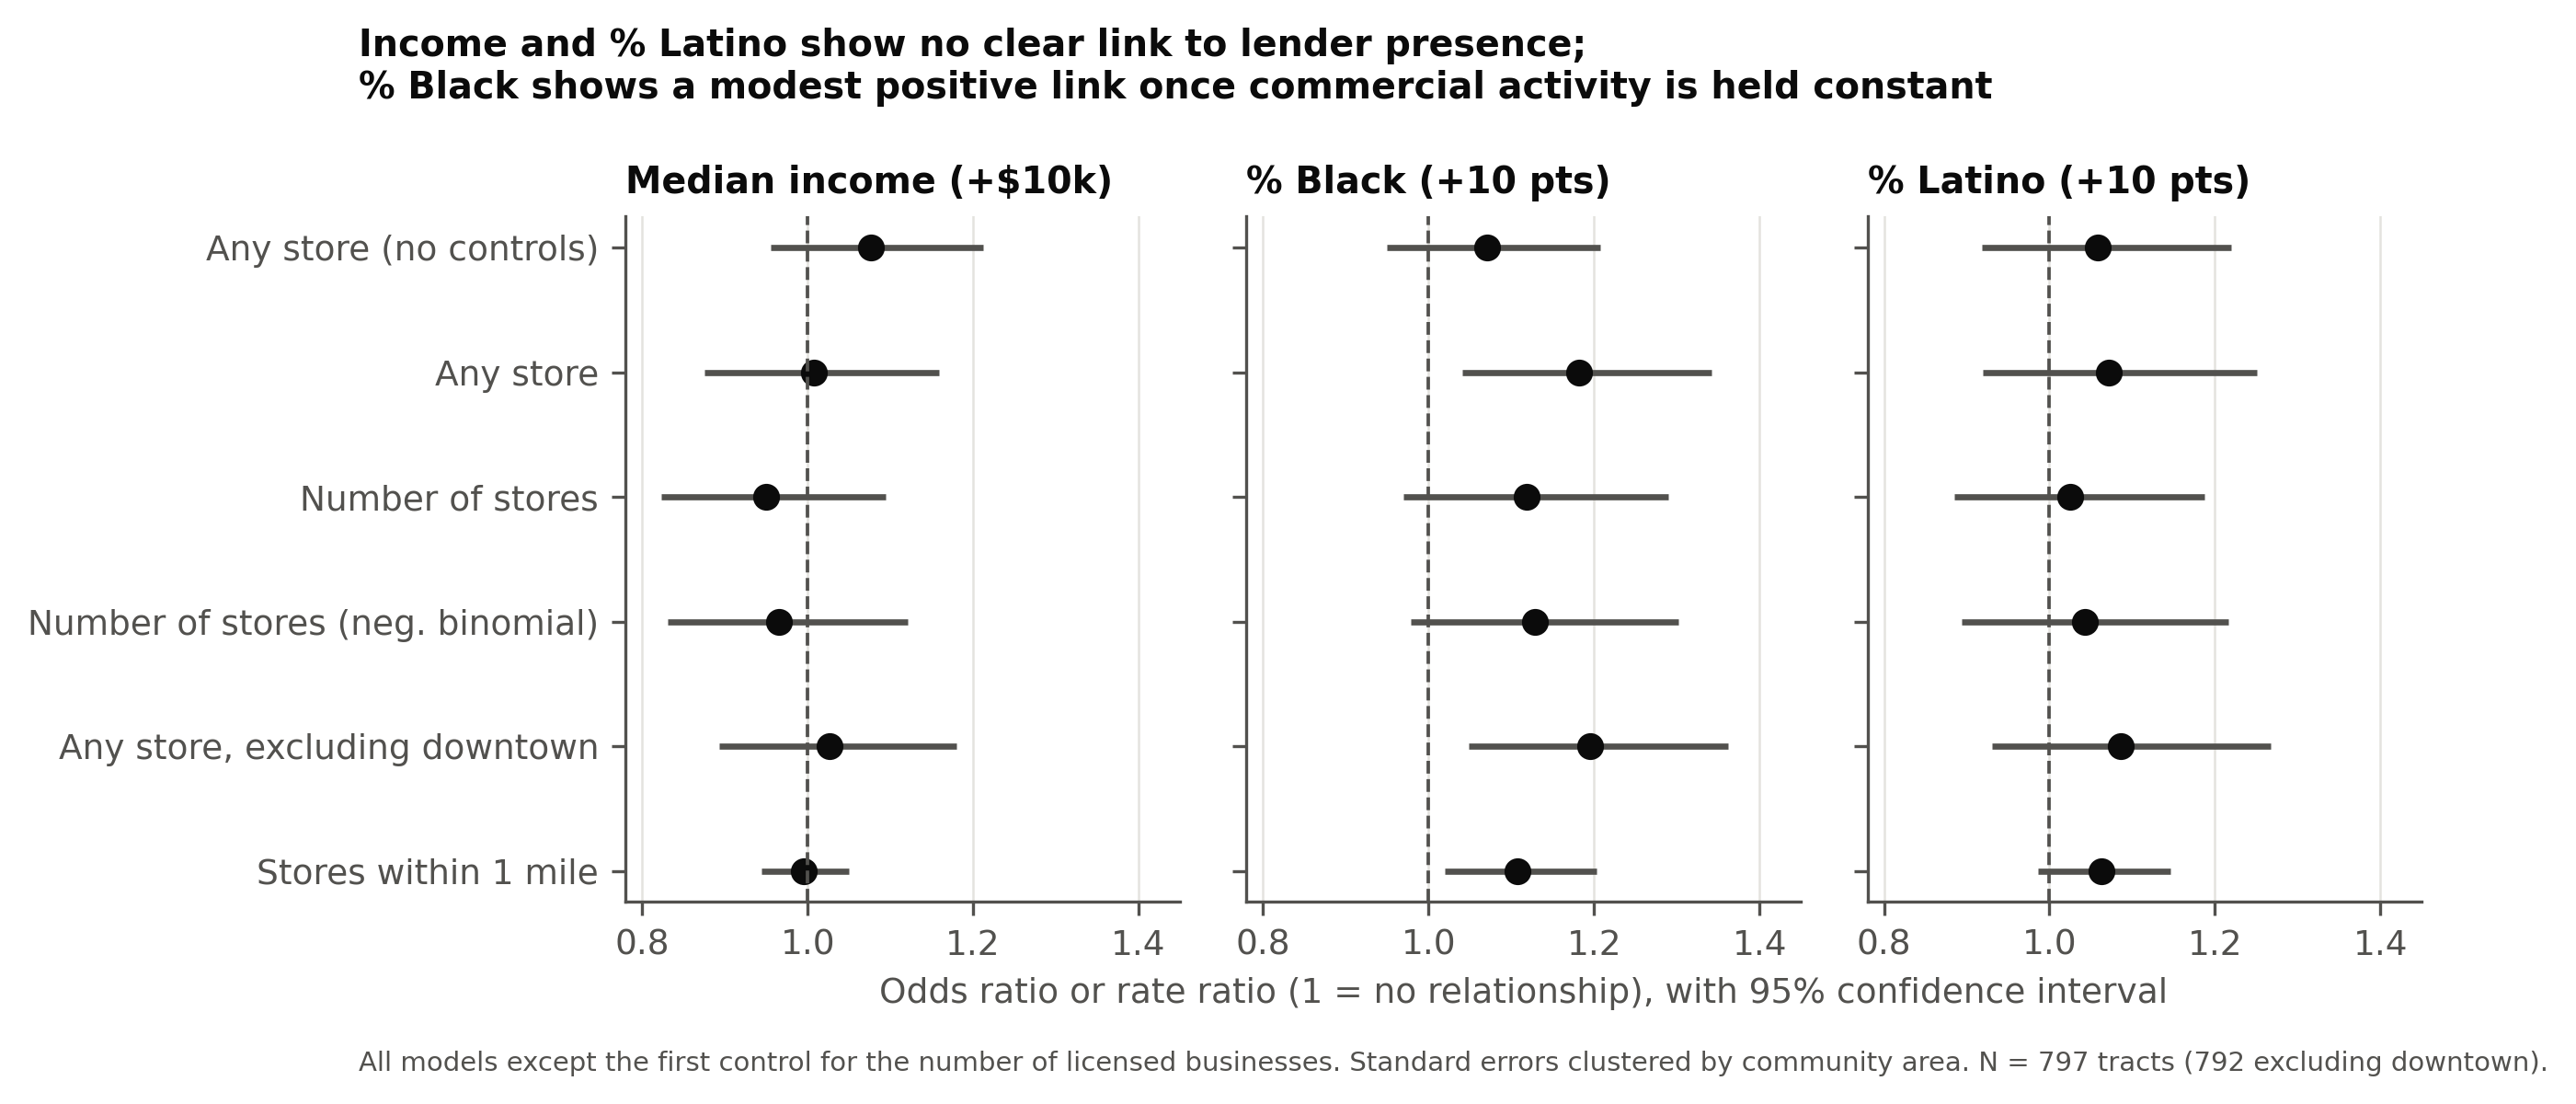

In [7]:
display(Image(FIGURES / "fig3_model_estimates.png", width=800))

**Reading it:** income has no relationship in any model. Commercial activity matters most. Among equally commercial tracts,
a higher Black share is linked to modestly higher odds of a lender, but that isn't significant in the count models,
so it's *suggestive*. Latino share shows no relationship.

## Step 3 - Question 2: did they close, and did the law cause it?

In [8]:
pd.read_csv(RESULTS / "store_counts_by_year.csv", index_col=0)

,high_cost,pawn,limited_license_locations
year,,,
2014,88,70,30465
2015,86,73,27114
2016,84,72,26022
2017,81,66,24508
2018,75,63,23757
2019,74,62,22548
2020,67,60,21520
2021,65,57,22281
2022,16,54,19838


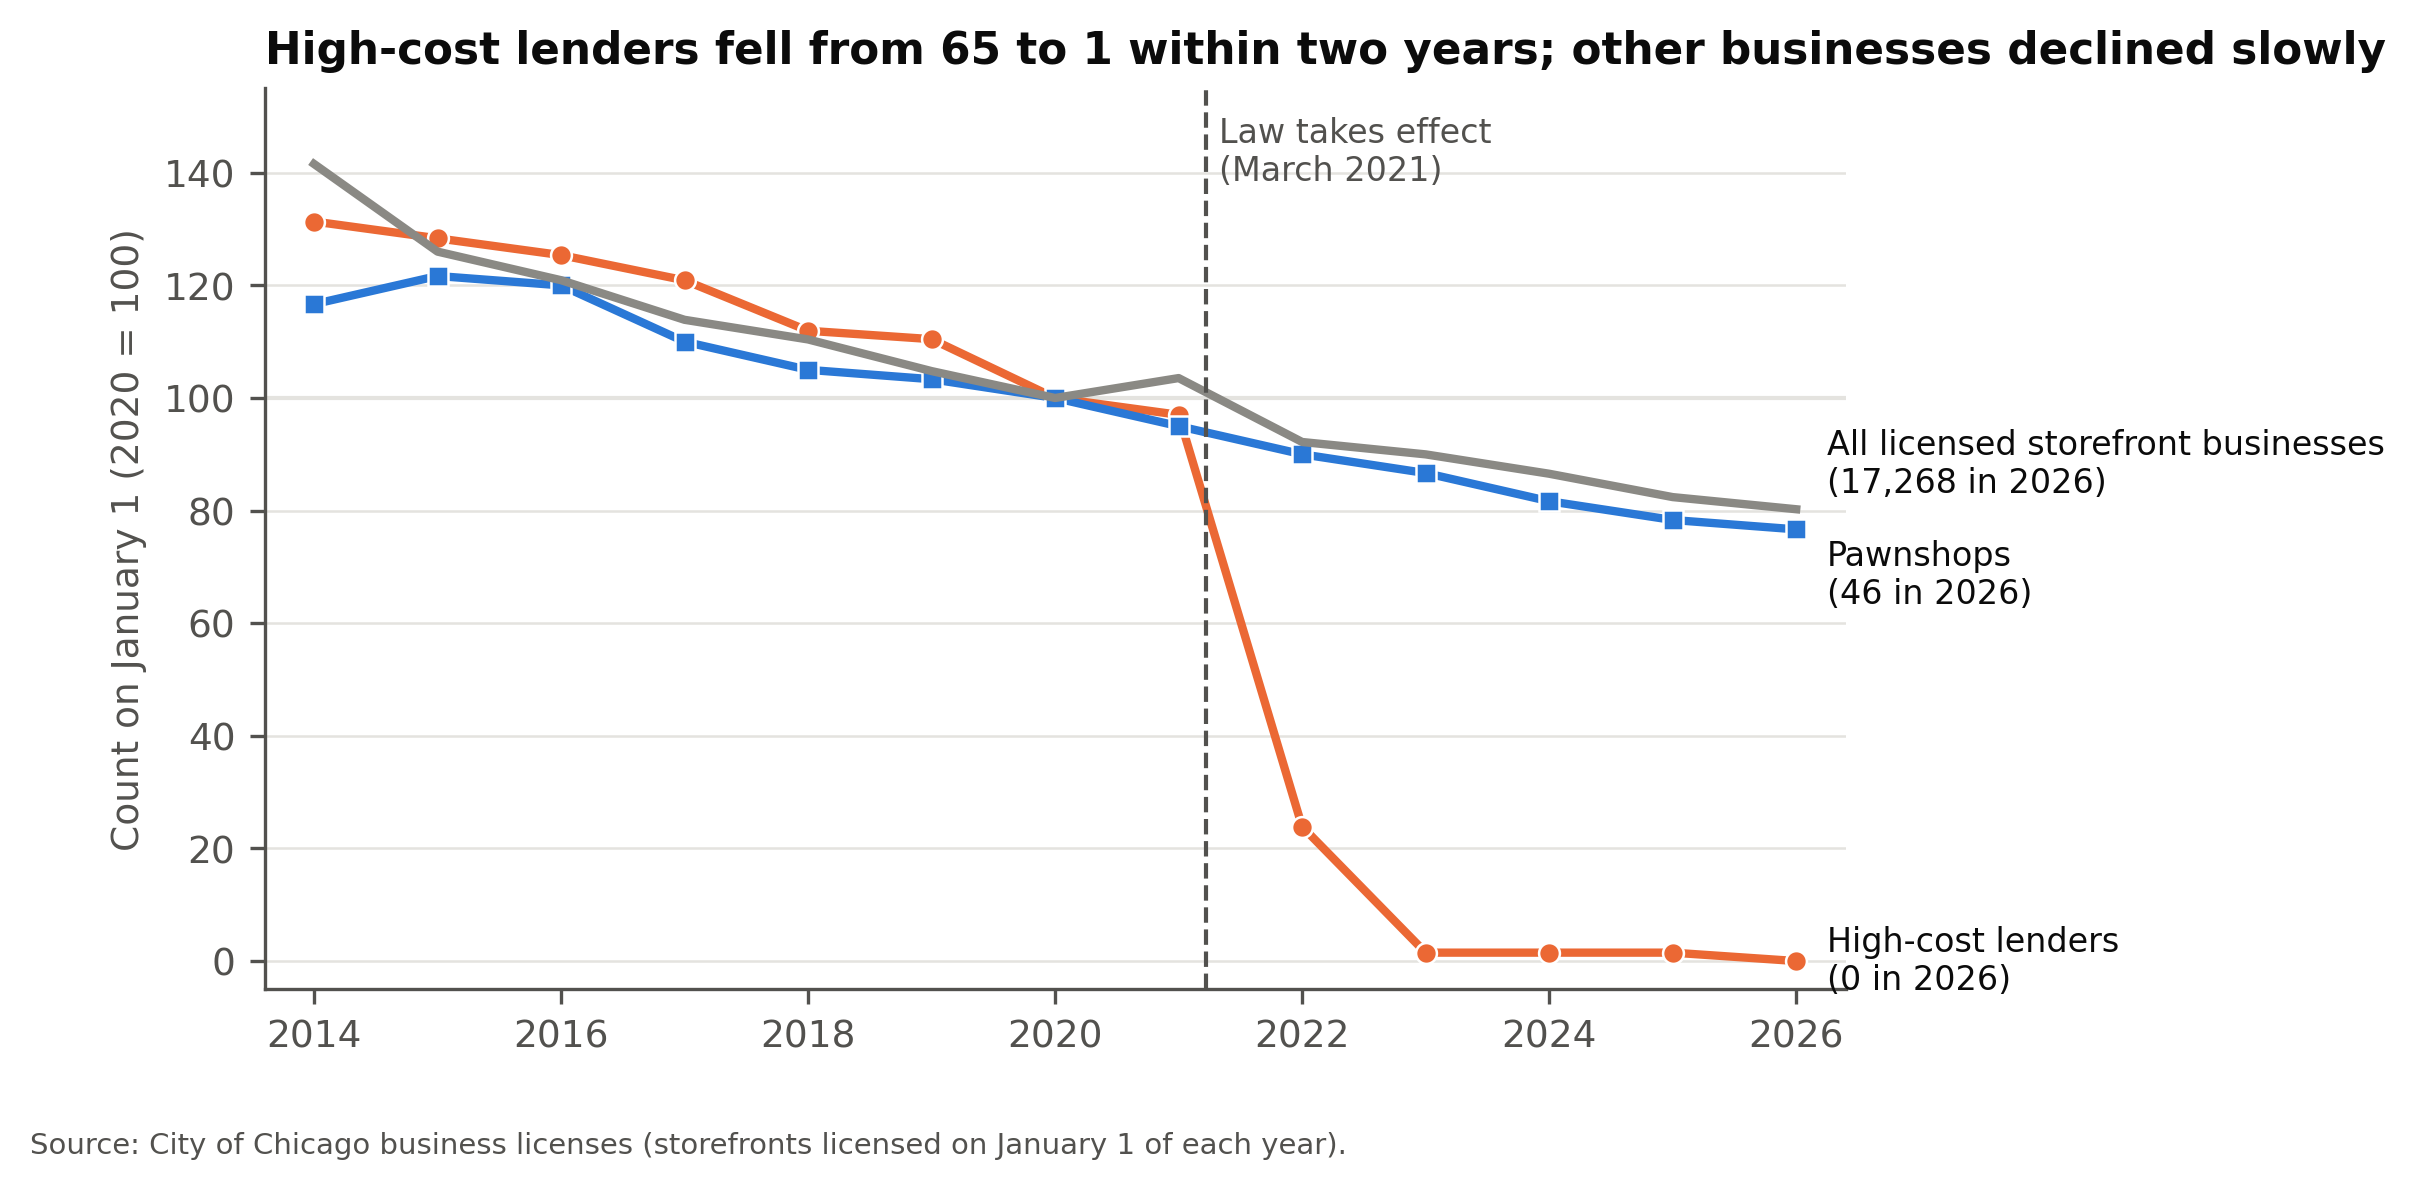

In [9]:
display(Image(FIGURES / "fig5_trend_index.png", width=700))

### Difference-in-differences

Compare the **change** in yearly closure rates for high-cost lenders with the change for pawnshops (the comparison group,
exempted from the cap by a court injunction). Shared shocks such as COVID-19 affect both groups, so they cancel out.

In [10]:
panel = load_panel()   # one row per store per year it was open; exit = 1 if it closed that year
panel.groupby(["category", "post"])["exit"].mean().unstack().rename(
    columns={0: "before (2014-20)", 1: "after (2021-25)"})

post,before (2014-20),after (2021-25)
category,,
high_cost,0.052,0.774
pawn,0.039,0.058


In [11]:
did = smf.ols("exit ~ high_cost * post", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["storefront_id"]})
print(f"DiD estimate: {did.params['high_cost:post']*100:.1f} percentage points "
      f"(95% CI {did.conf_int().loc['high_cost:post', 0]*100:.1f} to {did.conf_int().loc['high_cost:post', 1]*100:.1f})")

DiD estimate: 70.2 percentage points (95% CI 60.3 to 80.2)


**The key assumption** is that, without the law, both groups' closure rates would have moved in parallel.
We check whether they were already diverging before 2021:

In [12]:
pd.read_csv(RESULTS / "model_closure.csv")

,model,term,estimate_pct_points,ci_low,ci_high,p_value,n
0,B1 DiD 2x2,high_cost:post,70.227,60.292,80.162,0.000,1364
1,B2 DiD with year effects,high_cost:post,68.630,56.595,80.666,0.000,1364
2,B3 Pre-law trend difference (per year),high_cost:year,-0.124,-1.274,1.026,0.832,1021


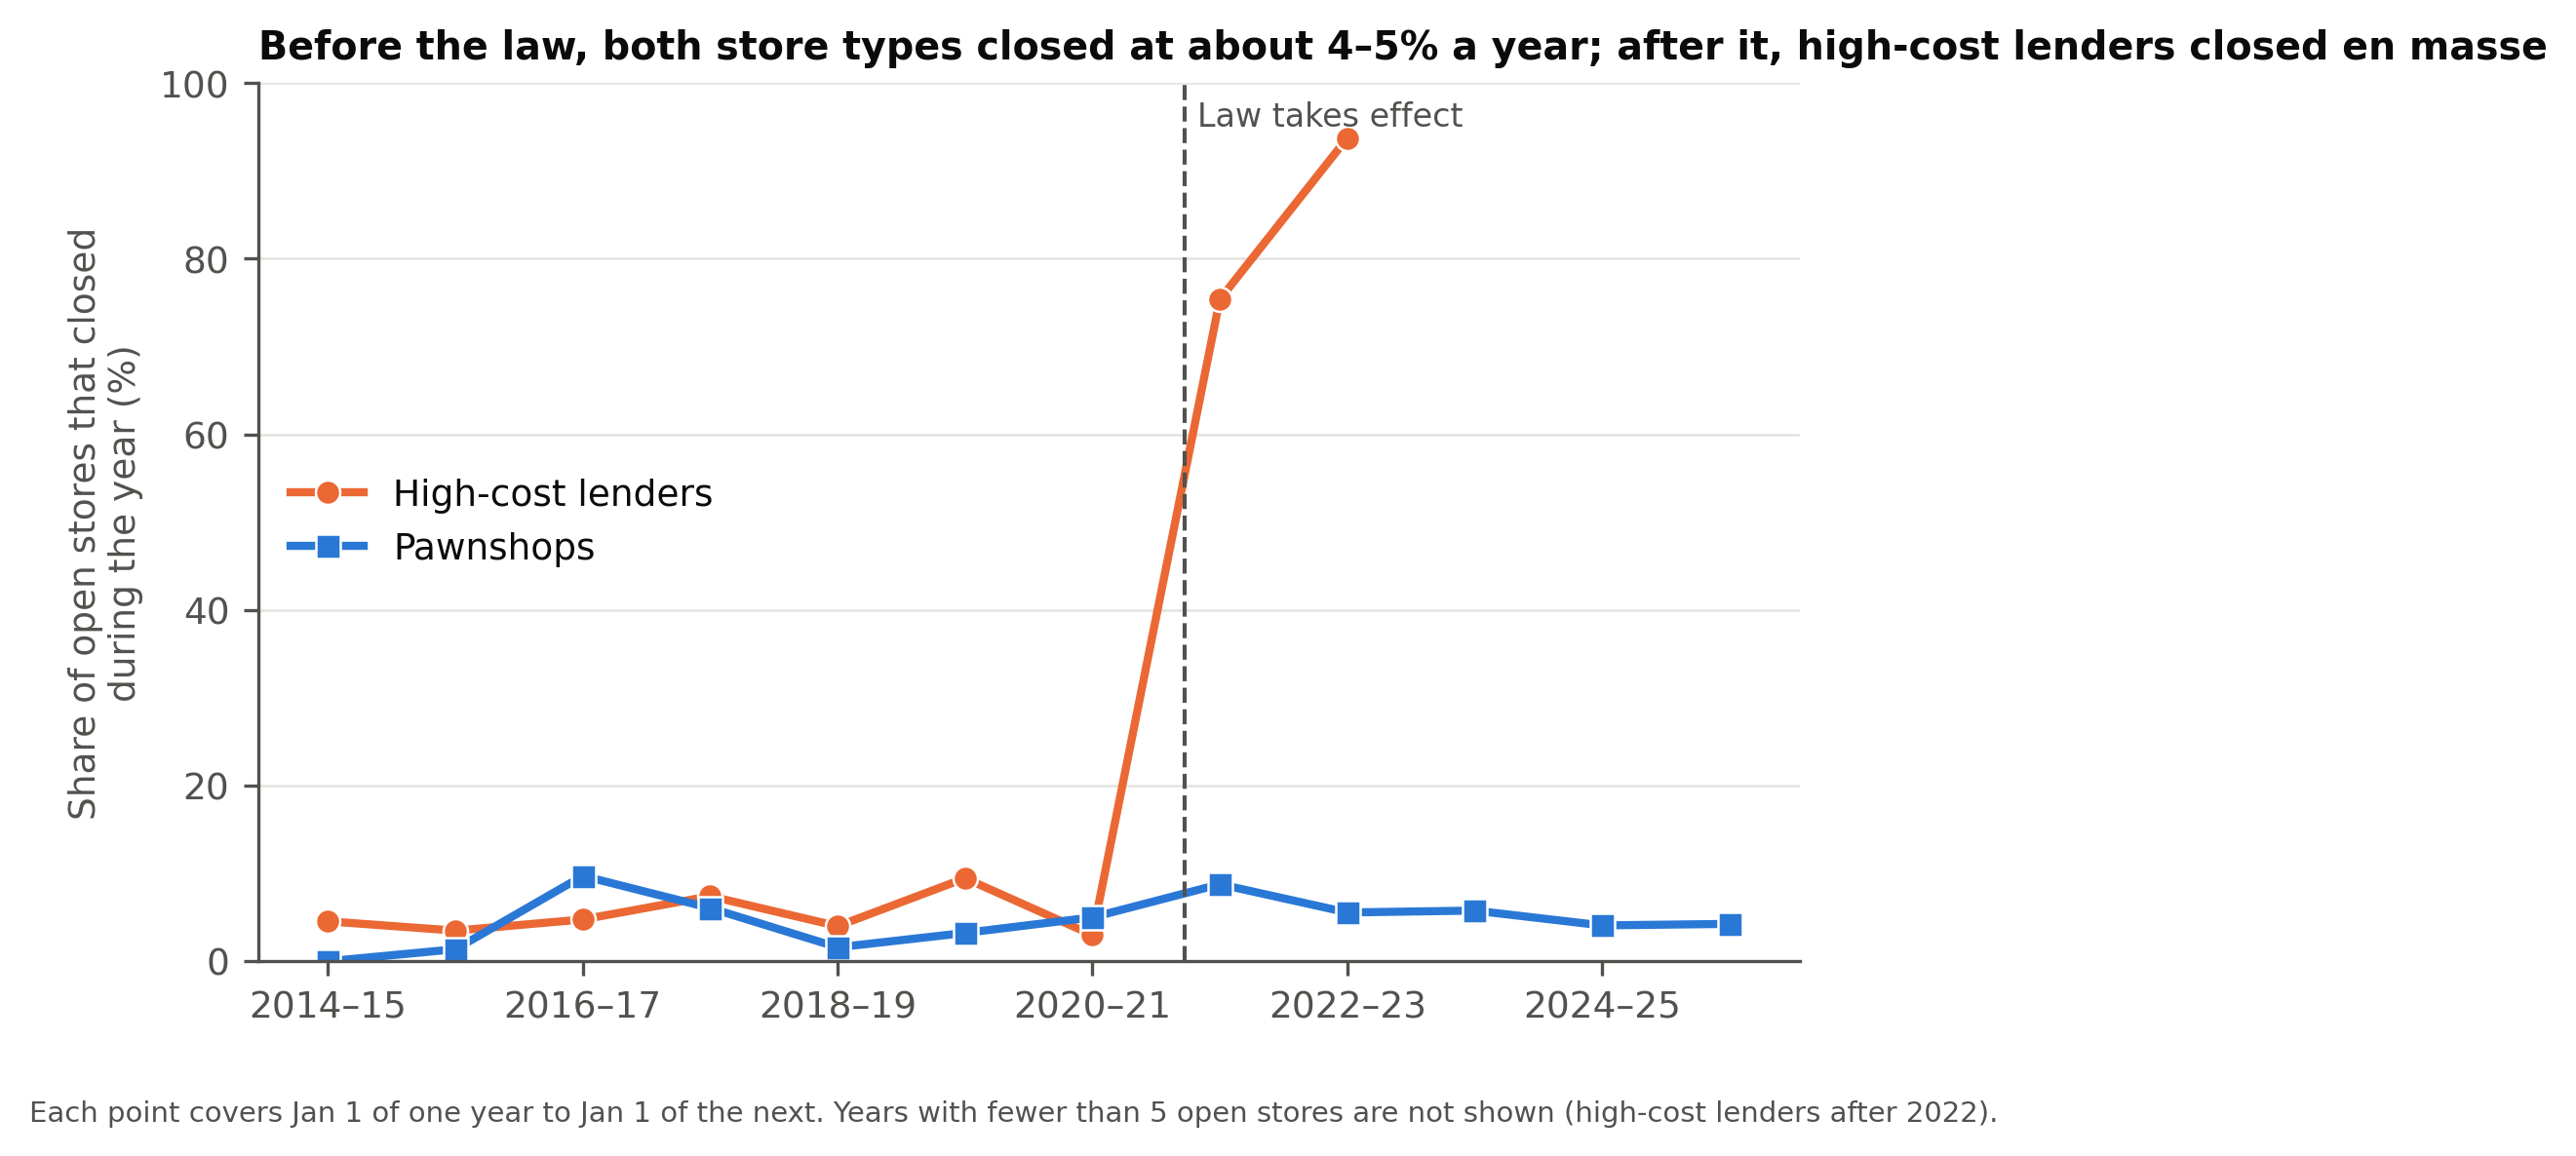

In [13]:
display(Image(FIGURES / "fig6_closure_rates.png", width=700))

## Step 4 - Question 3: did pawnshops fill the gap?

In [14]:
display(pd.read_csv(RESULTS / "pawn_openings.csv"))
pd.read_csv(RESULTS / "model_substitution.csv")

,period,openings,within_1mi_of_payday
0,2014 to law,5,5
1,after law,4,3


,model,estimate_pct_points,ci_low,ci_high,p_value,n
0,C2 Pawn closure DiD (near vs far from payday),-1.799,-8.792,5.194,0.614,725


The confidence interval runs from about −9 to +5 points, so the data can't tell us either way: it's **underpowered**, not a "no".

## Questions to be ready for
- *Why not just use the state's list of lenders?* There's no public list with addresses after 2011.
- *How do you know a lapsed license means a closed store?* Early cancellations, timing, the statewide license collapse, and the 2011 validation. (But see OneMain in `data/README.md`.)
- *Why control for businesses?* Lenders open on shopping streets. Without the control we'd rediscover where commercial corridors are.
- *Why pawnshops as the comparison?* Similar storefronts and neighborhoods, same shocks, but exempt from the cap.
- *What can't this show?* Effects on borrowers, online lending, and shocks unique to payday lending in 2021.